In [6]:
%matplotlib widget
import importlib
import numpy as np
import scipy
from mpl_toolkits.mplot3d import Axes3D
import os
import matplotlib.pyplot as plt
import time

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
import SMS_map
importlib.reload(SMS_map)
from SMS_map import *

import DTT_func
importlib.reload(DTT_func)
from DTT_func import *

In [7]:
x_val = np.linspace(17.9243e-6,19.0963e-6,25)
y_val = np.linspace(16e-6,18.5e-6,40)


X_val, Y_val = np.meshgrid(x_val, y_val)
xc, yc = 18.5e-6, 17.4e-6
fwhm = 400e-9
dy = 600e-9
amp = 1


airy_calc = airy(X_val,Y_val, xc, yc, amp, fwhm)
DTT_calc = abs(DTT(X_val,Y_val,xc,yc,amp,dy,fwhm,2))

    

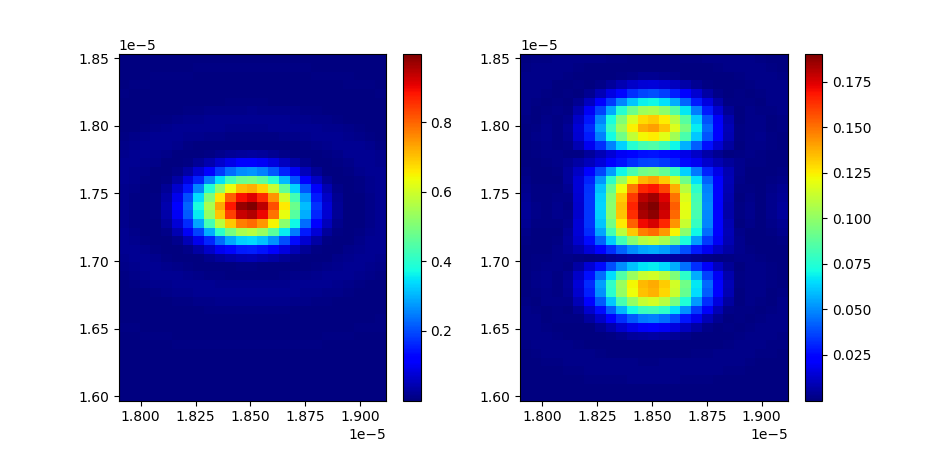

In [8]:
fig, (ax1, ax2) = plt.subplots(ncols=2, gridspec_kw = {'width_ratios':[1, 1]},figsize=(9.5,4.5))
im1 = ax1.pcolor(x_val,y_val,airy_calc,cmap='jet')
im2 = ax2.pcolor(x_val,y_val,DTT_calc,cmap='jet')
plt.colorbar(im2,ax = ax2)
plt.colorbar(im1,ax = ax1)

In [9]:
dtt_res = []

for val in FWHM :
    dtt_res.append(np.max(np.abs(DTT(X_val,Y_val,xc,yc,amp,dy,val,2))))
dtt_res = np.array(dtt_res)

NameError: name 'FWHM' is not defined

In [ ]:
fig = plt.figure()

plt.plot(FWHM*1e9, dtt_res/dtt_res.max())

In [ ]:
signal_interp = scipy.interpolate.interp1d(FWHM*1e9, dtt_res, bounds_error = "False", fill_value=0)
print(np.max(signal_interp(FWHM*1e9)))
max = np.max(signal_interp(FWHM*1e9))

print((signal_interp(400)- signal_interp(450))/max)